Load a real dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])

print(df.head())
print(df.shape)

       Month  Passengers
0 1949-01-01         112
1 1949-02-01         118
2 1949-03-01         132
3 1949-04-01         129
4 1949-05-01         121
(144, 2)


Visualize the data:

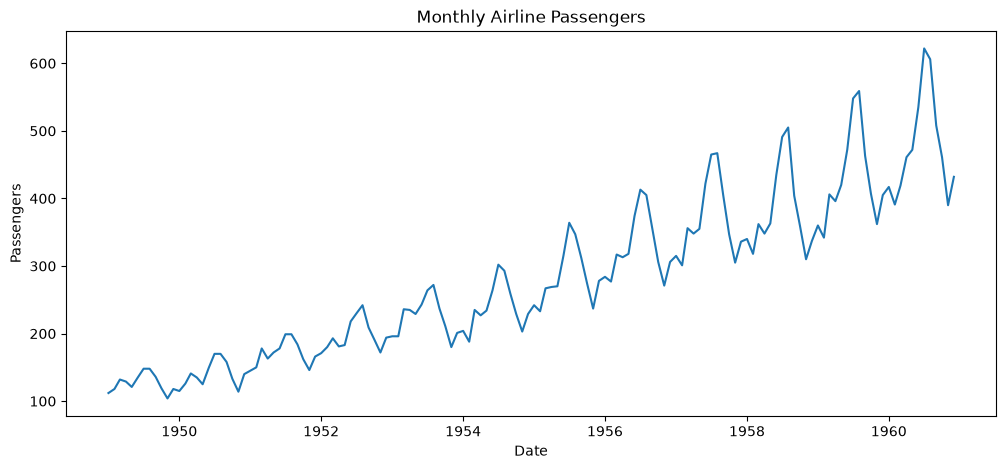

In [2]:
plt.figure(figsize=(12, 5))

plt.plot(df["Month"], df["Passengers"])

plt.xlabel("Date")
plt.ylabel("Passengers")
plt.title("Monthly Airline Passengers")

plt.show()

Prepare the dataset

In [3]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

values = df["Passengers"].values.astype("float32").reshape(-1, 1)

train_end = int(len(values) * 0.70)
val_end = int(len(values) * 0.85)

scaler = MinMaxScaler()

# Fit only on training data
scaler.fit(values[:train_end])

scaled = scaler.transform(values)

LOOKBACK = 12

X_train, y_train = [], []
X_val, y_val = [], []
X_test, y_test = [], []

for i in range(LOOKBACK, len(scaled)):

    X = scaled[i-LOOKBACK:i]
    y = scaled[i]

    if i < train_end:
        X_train.append(X)
        y_train.append(y)

    elif i < val_end:
        X_val.append(X)
        y_val.append(y)

    else:
        X_test.append(X)
        y_test.append(y)


X_train = np.array(X_train)
y_train = np.array(y_train)

X_val = np.array(X_val)
y_val = np.array(y_val)

X_test = np.array(X_test)
y_test = np.array(y_test)

print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(X_test.shape)

(88, 12, 1)
(88, 1)
(22, 12, 1)
(22, 12, 1)


Convert into PyTorch tensors

In [4]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

print("Device:", device)

Device: cpu


Build LSTM model

In [5]:
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(32, 1)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction


model = LSTMModel().to(device)

print(model)

LSTMModel(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


Train the model

In [6]:
import copy

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

best_val_loss = float("inf")
best_state = None

for epoch in range(50):

    model.train()

    train_loss = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = model(xb)

        loss = criterion(predictions, yb)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()

    with torch.no_grad():

        val_predictions = model(X_val.to(device))

        val_loss = criterion(
            val_predictions,
            y_val.to(device)
        ).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/50 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

model.load_state_dict(best_state)

Epoch 10/50 | Train: 0.0354 | Val: 0.1614
Epoch 20/50 | Train: 0.0120 | Val: 0.0439
Epoch 30/50 | Train: 0.0108 | Val: 0.0395
Epoch 40/50 | Train: 0.0106 | Val: 0.0409
Epoch 50/50 | Train: 0.0103 | Val: 0.0371


<All keys matched successfully>

Make predictions

In [7]:
model.eval()

with torch.no_grad():

    predictions = model(
        X_test.to(device)
    ).cpu().numpy()

    actual = y_test.numpy()

# Convert scaled values back to passenger numbers
predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(actual)

print("Predictions:", predictions[:5].flatten())
print("Actual:", actual[:5].flatten())

Predictions: [363.5331  370.1942  372.77502 377.28165 384.7433 ]
Actual: [405.99997 395.99997 420.      472.      548.     ]


Evaluate using MAE and RMSE

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 71.66189575195312
RMSE: 93.652412750887


Visualize predictions

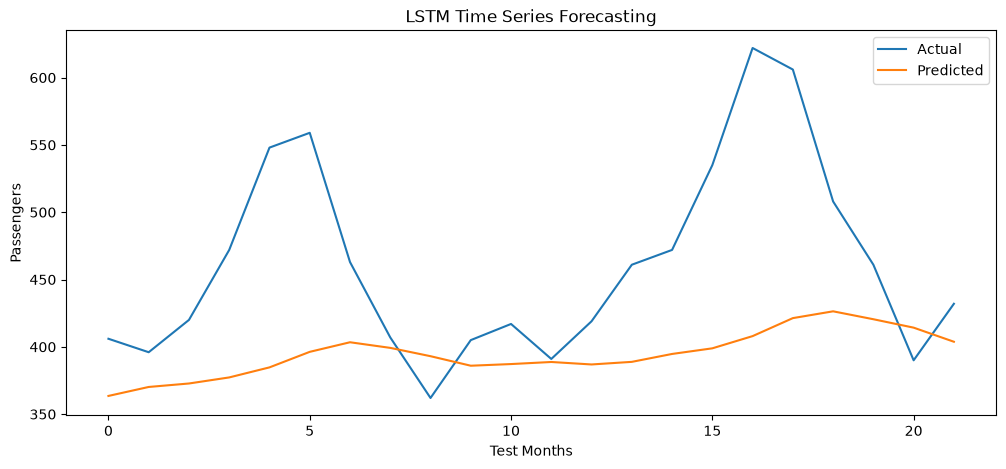

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(actual, label="Actual")

plt.plot(predictions, label="Predicted")

plt.title("LSTM Time Series Forecasting")

plt.xlabel("Test Months")
plt.ylabel("Passengers")

plt.legend()
plt.show()